In [1]:
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
from utils import *

fs = 125                                        # sampling frequency in Hz
dt = 1 / fs                                     # sampling interval in seconds
segLen = 15                                     # segment length in seconds
N = segLen * fs                                 # number of samples in a segment
t = np.arange(dt, segLen + dt, dt)              # time
initPressure = 130                              # initial cuff pressure in mmHg
def_rate = 4.15                                 # deflation rate in mmHg/s
cuffPressure = initPressure - def_rate * t      # cuff pressure in mmHg

resp_lowcut = 0.01                              # low cut-off frequency
resp_highcut = 1                                # high cut-off frequency
resp_filter_order = 8                           # filter order

data_dir = '../../../../../../data/physionet.org/files/mimicdb/1.0.0'
env_dir = '../results/envelopes'
fig_dir = '../figures'


subject = '039'
path = f'{data_dir}/{subject}/{subject}'
signals = wfdb.rdsamp(path)
bp_ch = signals[1]['sig_name'].index('ABP')
bp = signals[0][:, bp_ch]
resp_ch = signals[1]['sig_name'].index('RESP')
resp = signals[0][:, resp_ch]

path = f'{env_dir}/{subject}.npz'
data = np.load(path)
env_u = data['env_u']
env_d = data['env_d']

resp_filled = resp.copy()
nan_idx = np.isnan(resp_filled)
resp_filled[nan_idx] = np.interp(np.flatnonzero(nan_idx), np.flatnonzero(~nan_idx), resp_filled[~nan_idx])

sos = butter(resp_filter_order, [resp_lowcut, resp_highcut], btype='bandpass', fs=fs, output='sos')
resp_f = sosfiltfilt(sos, resp_filled)

k = 0
segment = bp[k * N:(k + 1) * N]
env_u_segment = env_u[k * N:(k + 1) * N]
env_d_segment = env_d[k * N:(k + 1) * N]
resp_segment = resp_f[k * N:(k + 1) * N]
indices = find_intersect(segment, cuffPressure)
t_valid = env_u_segment > 0

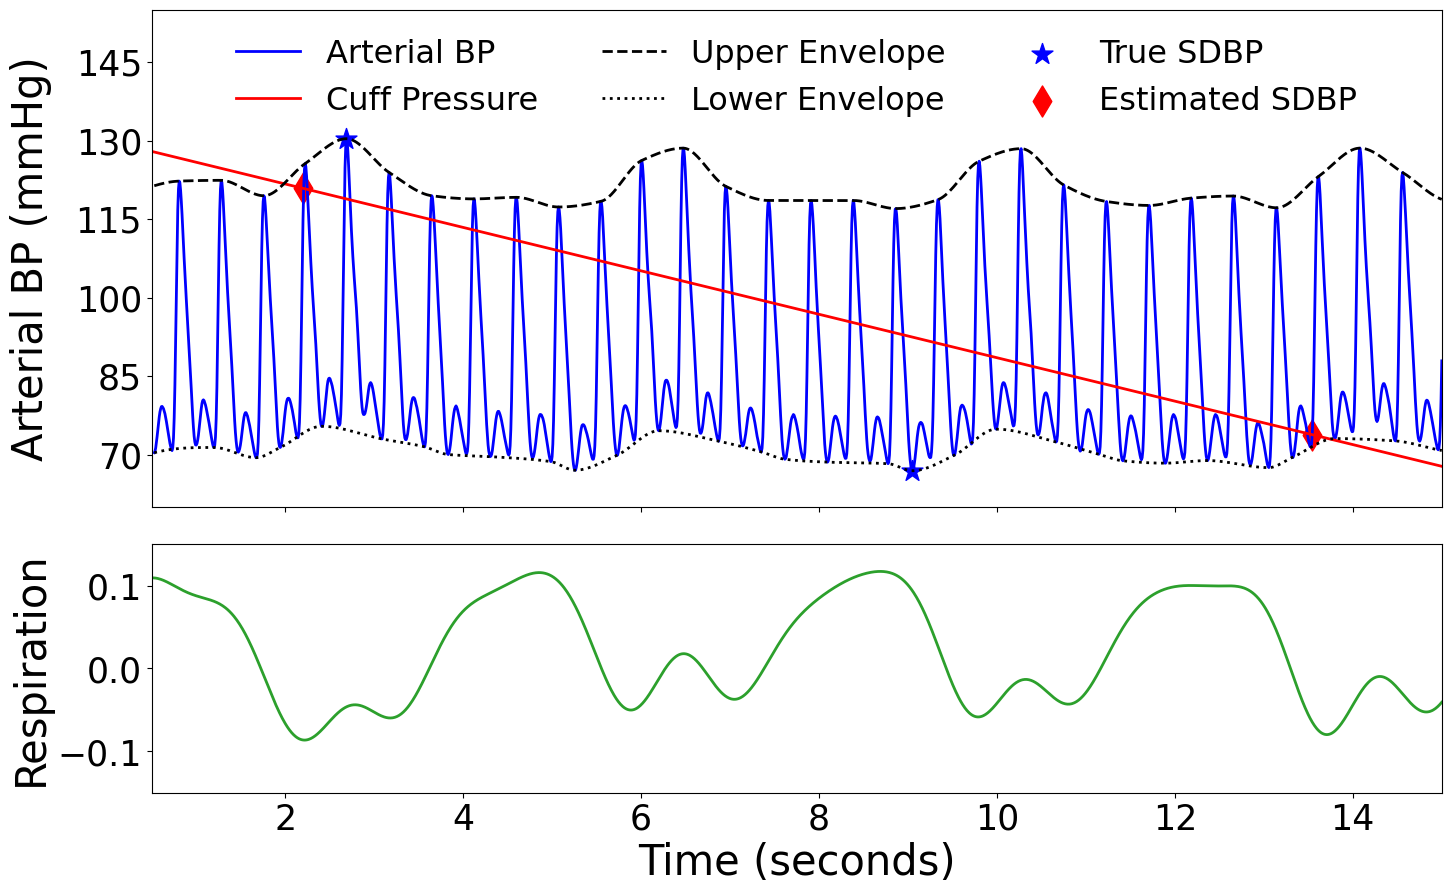

intersection_039.png was saved successfully!


In [2]:
label_fontsize = 30
tick_fontsize = 25
legend_fontsize = 23
marker_size = 250
line_width = 2
fig_size = (15, 9)
height_ratios = [3, 1.5]


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=fig_size, sharex=True, gridspec_kw={'height_ratios': height_ratios})

# ------------------------- BP -------------------------------
ax1.plot(t[t_valid], segment[t_valid], color='blue', label='Arterial BP', linewidth=line_width)
ax1.plot(t, cuffPressure, color='red', label='Cuff Pressure', linewidth=line_width)
ax1.plot(t[t_valid], env_u_segment[t_valid], color='black', label='Upper Envelope', linestyle='--', linewidth=line_width)
ax1.plot(t[env_d_segment > 0], env_d_segment[env_d_segment > 0], color='black', label='Lower Envelope', linestyle=':', linewidth=line_width)
ax1.scatter(t[np.argmin(segment)], np.min(segment), marker='*', color='blue', s=marker_size, label='True SDBP')
ax1.scatter(t[np.argmax(segment)], np.max(segment), marker='*', color='blue', s=marker_size)
ax1.scatter(t[indices[0]], cuffPressure[indices[0]], marker='d', color='red', s=marker_size, label='Estimated SDBP')
ax1.scatter(t[indices[-1]], cuffPressure[indices[-1]], marker='d', color='red', s=marker_size)
ax1.set_ylabel('Arterial BP (mmHg)', fontsize=label_fontsize)
ax1.set_xlim(0.5, 15)
ax1.set_ylim(60, 155)
ax1.set_yticks([70, 85, 100, 115, 130, 145])
ax1.tick_params(axis='both', labelsize=tick_fontsize)
ax1.legend(fontsize=legend_fontsize, ncol=3, loc='upper center', frameon=False)


# --------------------- RESPIRATION --------------------------
ax2.plot(t, resp_segment, color='C2', linewidth=line_width)
ax2.set_ylabel('Respiration', fontsize=label_fontsize)
ax2.set_xlabel('Time (seconds)', fontsize=label_fontsize)
ax2.set_xlim(0.5, 15)
ax2.set_ylim(-0.15, 0.15)
ax2.tick_params(axis='both', labelsize=tick_fontsize)


# ------------------- FIGURE GEOMETRY ------------------------

fig.subplots_adjust(left=0.12, right=0.98, bottom=0.10, top=0.97, hspace=0.10)
fig.align_ylabels([ax1, ax2])

# Get the exact physical dimensions of the BP subplot
fig.canvas.draw()
bp_pos = ax1.get_position()
bp_axes_width = bp_pos.width * fig.get_figwidth()
bp_axes_height = bp_pos.height * fig.get_figheight()
bp_left_margin = bp_pos.x0 * fig.get_figwidth()
bp_right_margin = (1 - bp_pos.x1) * fig.get_figwidth()
bp_top_margin = (1 - bp_pos.y1) * fig.get_figheight()

fig_path = f'{fig_dir}/intersection_{subject}.png'
fig.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)
print(f'intersection_{subject}.png was saved successfully!')

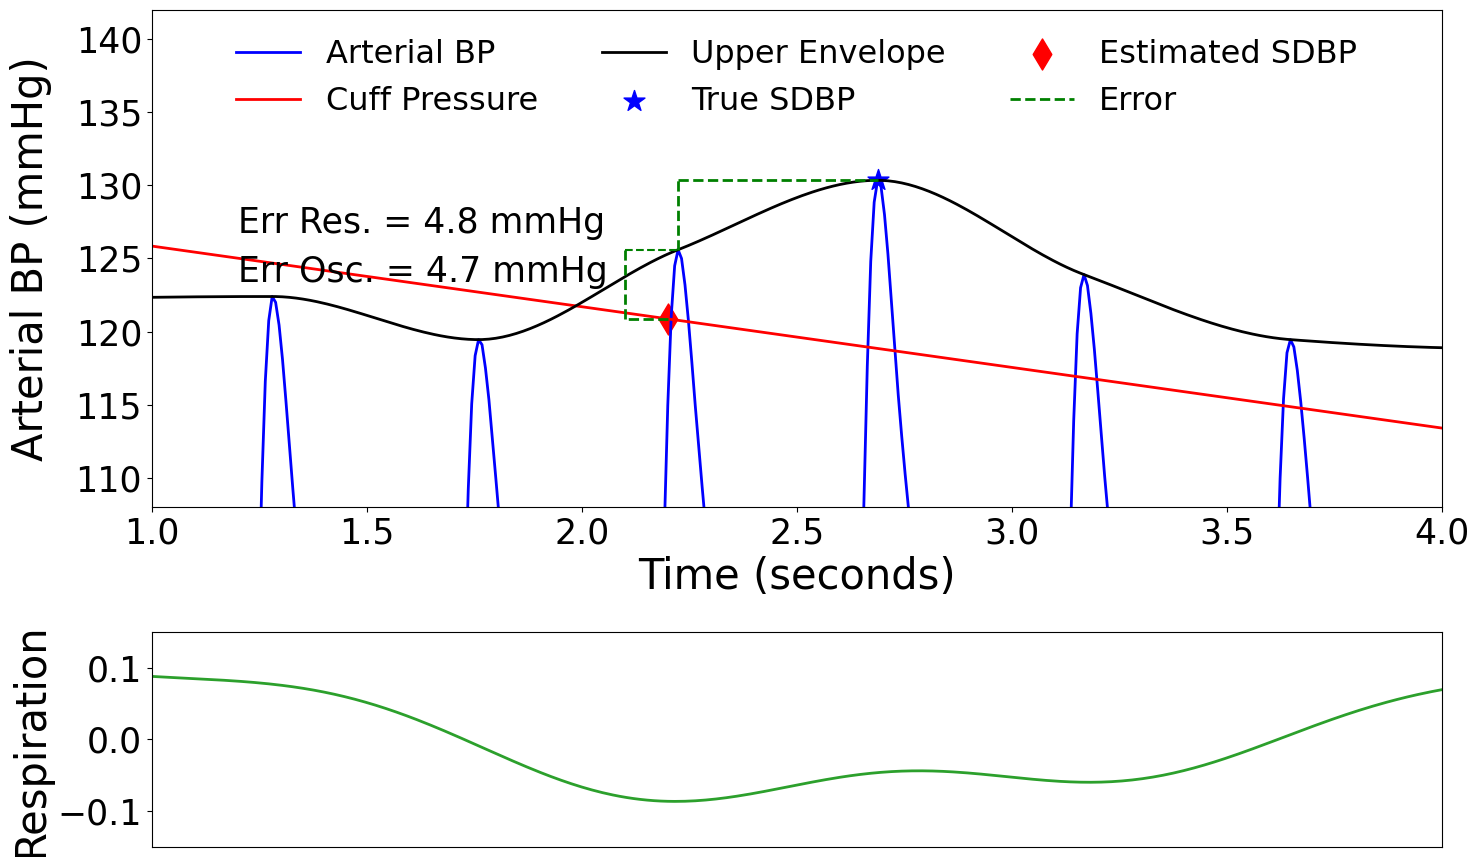

intersection_039_zoom_in.png was saved successfully!


In [3]:
# FIGURE 2: ZOOMED-IN ERROR PLOT
height_ratios = [3, 1.3]
fig_zoom, (ax1_zoom, ax2_zoom) = plt.subplots(2, 1, figsize=fig_size, sharex=False, gridspec_kw={'height_ratios': height_ratios})

# ------------------------- BP -------------------------------
ax1_zoom.plot(t[t_valid], segment[t_valid], color='blue', label='Arterial BP', linewidth=line_width)
ax1_zoom.plot(t, cuffPressure, color='red', label='Cuff Pressure', linewidth=line_width)
ax1_zoom.plot(t[t_valid], env_u_segment[t_valid], color='black', label='Upper Envelope', linewidth=line_width)
ax1_zoom.scatter(t[np.argmin(segment)], np.min(segment), marker='*', color='blue', s=marker_size, label='True SDBP')
ax1_zoom.scatter(t[np.argmax(segment)], np.max(segment), marker='*', color='blue', s=marker_size)
ax1_zoom.scatter(t[indices[0]], cuffPressure[indices[0]], marker='d', color='red', s=marker_size, label='Estimated SDBP')
ax1_zoom.scatter(t[indices[-1]], cuffPressure[indices[-1]], marker='d', color='red', s=marker_size)


temp = segment[indices[0]:indices[1]]
maxPindex = np.argmax(temp)
ax1_zoom.plot([t[indices[0]], 2.1], [cuffPressure[indices[0]], cuffPressure[indices[0]]], 'g--', lw=line_width)
ax1_zoom.plot([2.1, 2.1], [cuffPressure[indices[0]], temp[maxPindex]], 'g--', lw=line_width)
ax1_zoom.plot([t[indices[0] + maxPindex], t[indices[0] + maxPindex]], [temp[maxPindex], np.max(segment)], 'g--', lw=line_width)
ax1_zoom.plot([2.1, t[indices[0] + maxPindex]], [temp[maxPindex], temp[maxPindex]], 'g--', lw=1.5)
ax1_zoom.plot([t[indices[0] + maxPindex], t[np.argmax(segment)]], [np.max(segment), np.max(segment)], 'g--', lw=line_width, label='Error')
ax1_zoom.text(1.2, cuffPressure[indices[0]] + 2.5, f'Err Osc. = {temp[maxPindex] - cuffPressure[indices[0]]:.1f} mmHg', fontsize=tick_fontsize)
ax1_zoom.text(1.2, cuffPressure[indices[0]] + 5.9, f'Err Res. = {np.max(segment) - temp[maxPindex]:.1f} mmHg', fontsize=tick_fontsize)
ax1_zoom.set_ylabel('Arterial BP (mmHg)', fontsize=label_fontsize)
ax1_zoom.set_xlabel('Time (seconds)', fontsize=label_fontsize)
ax1_zoom.set_xlim(1, 4)
ax1_zoom.set_ylim(108, 142)
ax1_zoom.tick_params(axis='both', labelsize=tick_fontsize)
ax1_zoom.legend(fontsize=legend_fontsize, ncol=3, loc='upper center', frameon=False)


# --------------------- RESPIRATION --------------------------
ax2_zoom.plot(t, resp_segment, color='C2', linewidth=line_width)
ax2_zoom.set_ylabel('Respiration', fontsize=label_fontsize)
ax2_zoom.set_xlim(1, 4)
ax2_zoom.set_ylim(-0.15, 0.15)
ax2_zoom.tick_params(axis='y', labelsize=tick_fontsize)
ax2_zoom.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)
fig_zoom.subplots_adjust(left=0.12, right=0.98, bottom=0.04, top=0.97, hspace=0.35)
fig_zoom.align_ylabels([ax1_zoom, ax2_zoom])

# ------------------------- SAVE -----------------------------
fig_path = f'{fig_dir}/intersection_{subject}_zoom_in.png'
fig_zoom.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig_zoom)
print(f'intersection_{subject}_zoom_in.png was saved successfully!')